# Воронка покупки интернет-магазина косметики

Изучаем путь одного товара внутри сессии: просмотр, добавление в корзину и покупка. Данные охватывают октябрь и ноябрь 2019 года.

[Отчёт](docs/отчёт.md) | [Дашборд DataLens](https://datalens.yandex/hs3znlxv4pn40?_share_link=public)

## Постановка

Какая доля сессий доходит до каждого следующего этапа воронки? На каждом этапе сессия учитывается один раз. Учитываем события одного товара в строгом временном порядке. Период начала сессии: 2-30 октября и 2-29 ноября, UTC.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

root = Path.cwd()
assert (root / 'results/dashboard_funnel.csv').exists(), 'Запустите ноутбук из папки проекта'

## Проверка данных

Показатели ниже относятся к исходным файлам целиком. Полная проверка данных и построение воронки находятся в `src/analyze.py`.

In [2]:
for month in ('2019-Oct', '2019-Nov'):
    q = json.loads((root / 'results' / month / 'quality.json').read_text())
    print(month)
    display(pd.DataFrame([{'events':q['events'], 'users':q['users'], 'sessions':q['sessions'], 'missing_session':q['missing_session'], 'duplicate_rows':q['duplicate_rows']}]))

2019-Oct
2019-Nov


,events,users,sessions,missing_session,duplicate_rows
0,4102283,399664,873960,637,213155


,events,users,sessions,missing_session,duplicate_rows
0,4635837,368232,942022,813,246693


## Результаты воронки

Конверсия рассчитывается как число сессий на текущем этапе, делённое на число сессий на предыдущем этапе. Значение 100% на первом этапе показывает базу.

,month,stage,sessions,conversion_pct
0,Октябрь 2019,1 Просмотр,773750,100.00
1,Октябрь 2019,2 Корзина после просмотра,136149,17.60
2,Октябрь 2019,3 Покупка после корзины,13389,9.83
3,Ноябрь 2019,1 Просмотр,829585,100.00
4,Ноябрь 2019,2 Корзина после просмотра,107577,12.97
5,Ноябрь 2019,3 Покупка после корзины,16164,15.03


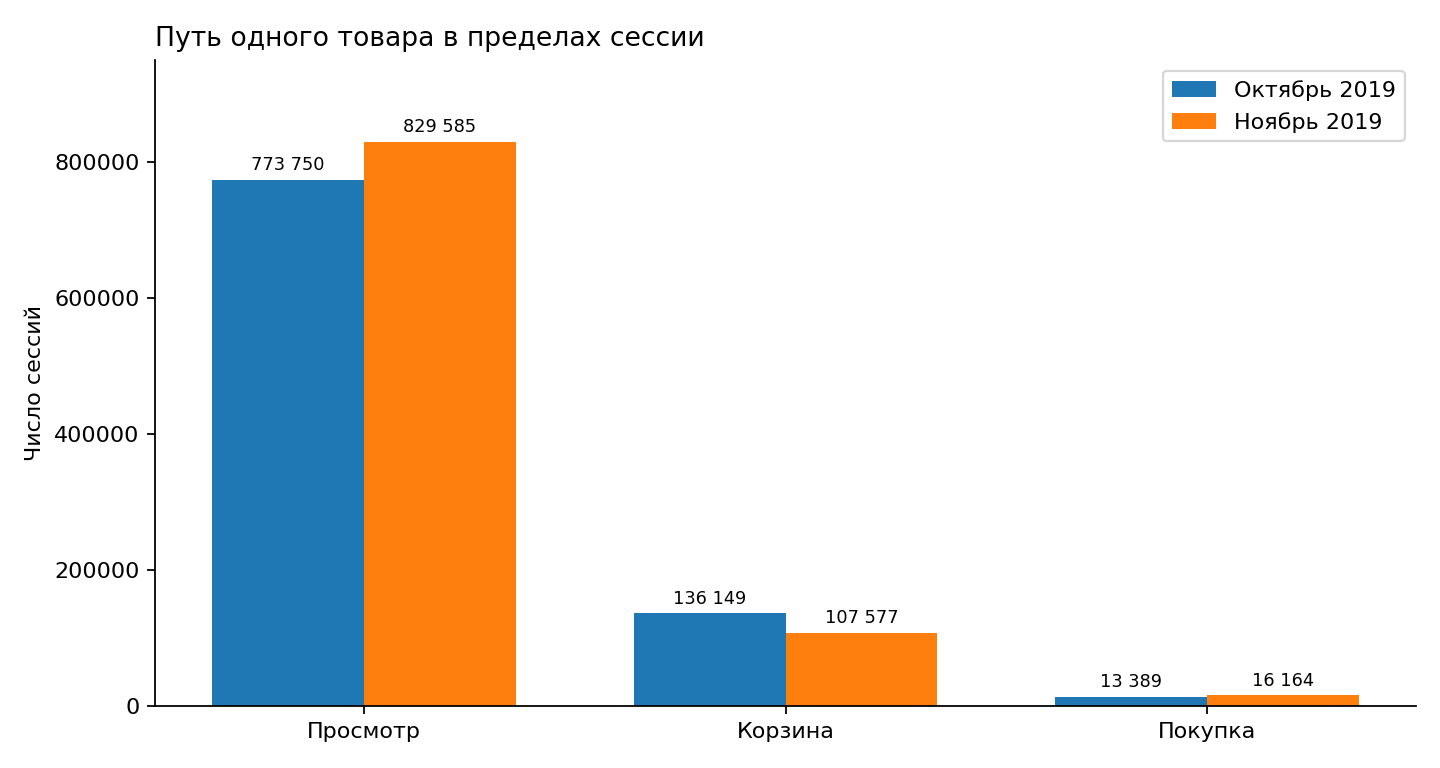

In [3]:
funnel = pd.read_csv(root / 'results/dashboard_funnel.csv')
funnel['conversion_pct'] = funnel['conversion_pct'].round(2)
display(funnel[['month', 'stage', 'sessions', 'conversion_pct']])
display(Image(filename=str(root / 'results/сравнение.png')))

В октябре конверсия из просмотра в корзину составила 17,60%, а из корзины в покупку 9,83%. В ноябре показатели составили 12,97% и 15,03%. Разница между месяцами описывает наблюдаемые данные и не объясняет её причины.

## Покупки вне последовательности

Таблицы ниже считают пары «сессия и товар» с событием покупки. Отсутствие просмотра в той же сессии не исключает, что товар просмотрели в другом посещении.

In [4]:
for month in ('2019-Oct', '2019-Nov'):
    print(month)
    display(pd.read_csv(root / 'results' / month / 'purchase_diagnostics.csv'))

2019-Oct
2019-Nov


,reason,pairs
0,Нет просмотра товара в сессии,183640
1,Полный путь,24869
2,Нет корзины после просмотра,16712
3,Просмотр не раньше покупки,792
4,Корзина не раньше покупки,26


,reason,pairs
0,Нет просмотра товара в сессии,243848
1,Полный путь,31189
2,Нет корзины после просмотра,22713
3,Просмотр не раньше покупки,834
4,Корзина не раньше покупки,45


## Вывод

Около половины сессий с покупкой не попали на последний этап выбранной воронки. Текстовые названия категорий отсутствуют у большинства просмотренных пар, поэтому сравнить основные категории косметики не получилось. Определения, проверки и подробные результаты приведены в [отчёте](docs/отчёт.md).